# 📘 **Regularització: Ridge, Lasso i Elastic Net - Wine Alcohol**

### **📚 02 Models Supervisats - Regularització**  
##### 🗂️ M0572 Sistemes d'aprenentatge automàtic  
###### 👤 *Robert Ventura Vall-llovera*  

---


**🎯 Objectiu:** L'objectiu d'aquest Notebook és veure què passa quan una regressió polinòmica s'ajusta *massa bé* als exemples d'entrenament i comprovar si Ridge, Lasso i Elastic Net milloren les prediccions en observacions noves.

**📦 Datasets**
[Wine — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/109/wine).

Són **178 mostres reals de vi**, analitzades químicament. El dataset normalment s'utilitza per a models de classifiació, ** però aquí adaptem el problema a regressió** per intentar predir la concentració d'**alcohol** (variable contínua) a partir de les sis mesures químiques.

* `malic_acid`: Quantitat d'àcid màlic (g/L grams per litre), un àcid orgànic que contribueix a l'acidesa del vi.
* `ash`: Contingut de cendres (g/L grams per litre), relacionat amb els minerals presents al vi.
* `magnesium`: Quantitat de magnesi (mg/L. mil·ligrams per litre) present al vi.
* `total_phenols`: Contingut total de compostos fenòlics (mg/L mil·ligrams per litre), relacionats amb les propietats organolèptiques del vi.
* `color_intensity`: Intensitat del color del vi, determinada mitjançant una mesura espectrofotomètrica (sense unitats).
* `proline`: Concentració de prolina (mg/L mil·ligrams per litre), un aminoàcid present al vi.
* `alcohol`: Contingut d'alcohol del vi (% vol. percentatge d'alcohol en volum)



## 1\. Carreguem el dataset i preparem les dades

Escollim sis variables d'entrada i l'alcohol com a `y`. Primer separem un **25 % de test que no utilitzarem per entrenar ni ajustar hiperparàmetres**. Després ens quedem amb només **80 observacions reals d'entrenament** per simular un projecte amb poques dades etiquetades: això facilitarà mostrar l'overfitting. Les altres observacions de la part d'entrenament queden fora d'aquesta pràctica; no es transformen ni es fabriquen.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, r2_score
RANDOM_STATE= 54

# Carraguem el dataset
df = load_wine(as_frame=True).frame
variables = ["malic_acid", "ash", "magnesium", "total_phenols",
             "color_intensity", "proline"]
X = df[variables]
y = df["alcohol"]  # variable objectiu

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

# Del conjunt d'entrenament agafem 80 registres reals per fer visible l'overfitting.
X_train, y_train = X_dev.iloc[:80], y_dev.iloc[:80]
X_train, y_train = X_dev, y_dev
print(f"Mostres totals: {len(df)} | train: {len(X_train)} | test: {len(X_test)}")
print("Variables predictives:", list(X_train.columns))
display(df[variables + ["alcohol"]].head())

Mostres totals: 178 | train: 133 | test: 45
Variables predictives: ['malic_acid', 'ash', 'magnesium', 'total_phenols', 'color_intensity', 'proline']


,malic_acid,ash,magnesium,total_phenols,color_intensity,proline,alcohol
0,1.71,2.43,127.0,2.80,5.64,1065.0,14.23
1,1.78,2.14,100.0,2.65,4.38,1050.0,13.20
2,2.36,2.67,101.0,2.80,5.68,1185.0,13.16
3,1.95,2.50,113.0,3.85,7.80,1480.0,14.37
4,2.59,2.87,118.0,2.80,4.32,735.0,13.24


## 2\. Model polinòmic

Anem a crear un model mitjanánt un polinomi de grau 4 amb `PolynomialFeatures(degree=4)` obtenim les potències i interaccions de les sis variables fins a quart grau.
Això crea **209 característiques/termes polinòmiques** a partir de només sis variables. El model té més coeficients que les 80 observacions d'entrenament: pot *memoritzar* les dades en lloc d'aprendre una pauta general.


In [10]:
GRAU = 4

def crear_model(regressor):
    return Pipeline([
        ("polinomis", PolynomialFeatures(degree=GRAU, include_bias=False)),
        ("escala_termes", MinMaxScaler()),
        ("model", regressor),
    ])

base = crear_model(LinearRegression())  # Sense cap regularització
base.fit(X_train, y_train)
n_termes = base.named_steps["polinomis"].n_output_features_
print(f"Variables originals: {X_train.shape[1]} → termes polinòmics: {n_termes}")
print(f"Sense regularització | MAE train: {mean_absolute_error(y_train, base.predict(X_train)):.3f}")
print(f"Sense regularització | MAE test : {mean_absolute_error(y_test, base.predict(X_test)):.3f}")

Variables originals: 6 → termes polinòmics: 209
Sense regularització | MAE train: 0.000
Sense regularització | MAE test : 2.616


## 3\. Intentem corregir el sobreajust: Ridge, Lasso i Elastic Net

Tots tres mantenen el **mateix polinomi de grau 4**, però introdueixen una penalització als coeficients:

- **Ridge (L2):** penalitza la suma dels coeficients **al quadrat**. Sol reduir-los, però normalment no els anul·la exactament.
- **Lasso (L1):** penalitza la suma dels valors **absoluts**. Pot deixar coeficients exactament en zero i seleccionar termes.
- **Elastic Net (L1 + L2):** combina les dues penalitzacions; `l1_ratio` regula quina proporció és L1.

`alpha` controla la intensitat de la regularització. **No decidim `alpha` mirant el test**: el busquem amb validació creuada de 4 folds, feta només sobre les 80 dades d'entrenament. La mètrica de selecció és el MAE (com més petit, millor).

In [11]:
# Modifica aquests valors i torna a executar per experimentar.
ALPHA_RIDGE = 100
ALPHA_LASSO = 0.1
ALPHA_ELASTIC = 0.1
L1_RATIO = 0.5

models = {
    "Sense regularització": base,
    "Ridge": crear_model(Ridge(alpha=ALPHA_RIDGE)),
    "Lasso": crear_model(Lasso(alpha=ALPHA_LASSO, max_iter=30000, tol=0.001)),
    "Elastic Net": crear_model(ElasticNet(alpha=ALPHA_ELASTIC, l1_ratio=L1_RATIO,
                                          max_iter=30000, tol=0.001)),
}

for nom, model in models.items():
    model.fit(X_train, y_train)

## 4\. Mesuem el l'overfitting de cada model

Compareu el **MAE de train** (dades conegudes) amb el **MAE de test** (dades que el model no ha vist). Un MAE de train pràcticament zero i un MAE de test elevat és un senyal típic de sobreajustament. Observeu també quants coeficients queden en zero.

,MAE train,MAE test,R² test,Coef. no nuls
Model,,,,
Sense regularització,0.000,2.616,-19.262,209
Ridge,0.427,0.521,0.398,209
Lasso,0.592,0.661,0.119,1
Elastic Net,0.477,0.572,0.290,26


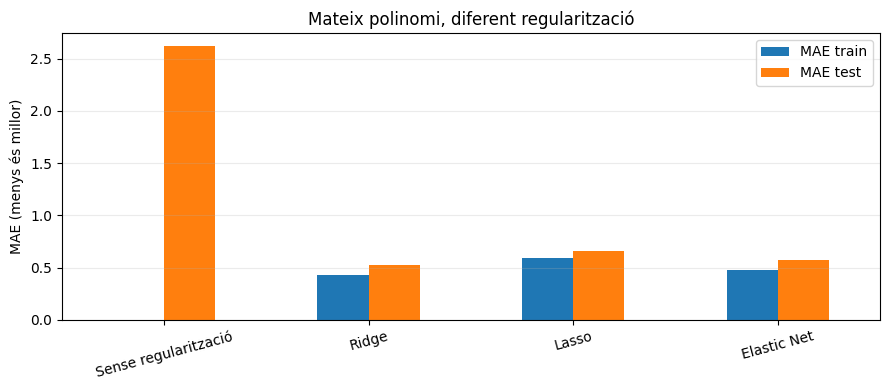

In [12]:
files = []
for nom, model in models.items():
    coef = model.named_steps["model"].coef_
    files.append({
        "Model": nom,
        "MAE train": mean_absolute_error(y_train, model.predict(X_train)),
        "MAE test": mean_absolute_error(y_test, model.predict(X_test)),
        "R² test": r2_score(y_test, model.predict(X_test)),
        "Coef. no nuls": np.count_nonzero(np.abs(coef) > 1e-6),
    })
resultats = pd.DataFrame(files).set_index("Model")

#Mostrem la taula amb el MAE train/test
display(resultats.round(3))

ax = resultats[["MAE train", "MAE test"]].plot.bar(figsize=(9, 4), rot=15)
ax.set_title("Mateix polinomi, diferent regularització")
ax.set_ylabel("MAE (menys és millor)")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 5\. Una altra diferència: els coeficients

La regularització **no elimina variables del dataset original**. Penalitza els coeficients dels **209 termes polinòmics**. Ridge sol mantenir-los, encara que més petits; Lasso pot anul·lar-ne molts; Elastic Net combina els dos comportaments. Comptem els coeficients diferents de zero per veure-ho.

,Coeficients no nuls,Coeficients en zero
Model,,
Sense regularització,209,0
Ridge,209,0
Lasso,1,208
Elastic Net,26,183


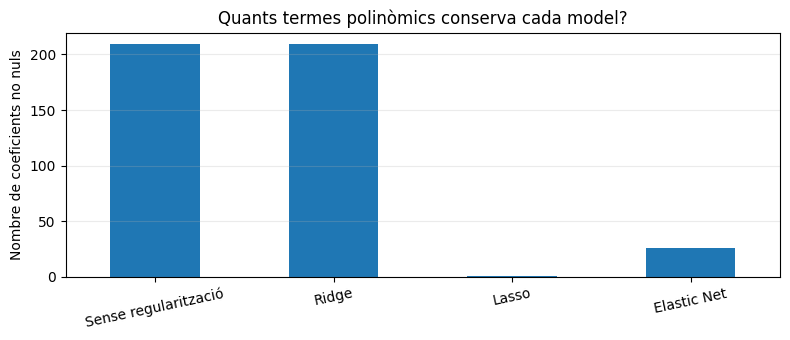

In [13]:
coef = []
for nom, model in models.items():
    pesos = model.named_steps["model"].coef_
    coef.append({
        "Model": nom,
        "Coeficients no nuls": np.count_nonzero(np.abs(pesos) > 1e-6),
        "Coeficients en zero": np.count_nonzero(np.abs(pesos) <= 1e-6),
    })
resum_coef = pd.DataFrame(coef).set_index("Model")
display(resum_coef)

ax = resum_coef["Coeficients no nuls"].plot.bar(figsize=(8, 3.5), rot=12)
ax.set_title("Quants termes polinòmics conserva cada model?")
ax.set_ylabel("Nombre de coeficients no nuls")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 6\. Conclusions

**Què podem observar?**

El model sense regularització pot aconseguir un **MAE d'entrenament** pràcticament **zero**, però una predicció molt pitjor amb el test.

Ridge, Lasso i Elastic Net accepten una mica més d'error d'entrenament a canvi de **generalitzar millor**. Lasso acostuma a seleccionar menys termes i Ridge acostuma a conservar-los; quin obté el MAE test més baix depèn de les dades i dels hiperparàmetres.

> 💡**Idea essencial:** regularitzar no significa «fer que train sigui millor». Significa **controlar la complexitat** per reduir l'error amb dades no vistes. Un model de grau més baix també pot ser una bona solució.





## ✏️ Actvitat 1

1. Canvia `GRAU = 4` per `2` i executa-ho de nou. Encara hi ha overfitting? Necessitem regularitzar tant?
2. Canvia les `80` observacions de train per `120`. Com afecta el resultat a tots els models?
3. A Lasso, prova un valor d'`alpha` força més alt que l'òptim. Què passa amb el nombre de coeficients no nuls? I amb el MAE de train i test?

##✏️ Actvitat 2

Com sabem quin és el millor valor per `alpha`? Busca a la documentació de de scikit-learn  documentació de la classe `LassoCV`, `RidgeCV` i `ElasticNetCV`. Què fan? i reescriu el notebook anterior utiltzant aquestes classes.
